# Image Pixel Manipulator (Synthetic Images)

### Objective
Treat an image as a 3D NumPy array `(Height, Width, Channels)` and learn how to create, crop, recolor, flip, brighten, and filter images using **pure NumPy**.

---

### NumPy Topics Covered
- **Array Creation:** `np.zeros`, `np.ones`, `np.full`, `np.random`
- **Indexing & Slicing:** 3D array slicing `img[y1:y2, x1:x2, c]`, step slicing `[::step]`, negative step slicing `[::-1]`
- **Data Types & Memory:** `uint8` vs `float32` vs `float64`, memory footprints with `nbytes`
- **Arithmetic Safety:** Avoiding `uint8` wrap-around overflow bugs with `astype` and `np.clip`
- **Boolean Masking:** Filtering and modifying pixels based on conditions
- **Visualization:** Matplotlib `plt.imshow` display rules for integer vs normalized float images


In [3]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Matplotlib visualization styling
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 9

print(f"NumPy Version: {np.__version__}")
print("Ready to manipulate image pixels with NumPy!")


NumPy Version: 2.5.1
Ready to manipulate image pixels with NumPy!


## 1. Creating Blank Canvases and Filling Regions

### Image as a 3D Tensor
In computer vision and image processing:
- An image is represented as a 3-dimensional array of shape **`(Height, Width, Channels)`**:
  - **Axis 0 (Height / Rows):** $Y$-coordinate from top ($0$) to bottom ($H-1$).
  - **Axis 1 (Width / Columns):** $X$-coordinate from left ($0$) to right ($W-1$).
  - **Axis 2 (Channels):** Color channels: index `0` is Red ($R$), index `1` is Green ($G$), index `2` is Blue ($B$).
- Standard digital colors use **`np.uint8`** (8-bit unsigned integers), with values ranging from $0$ (darkest) to $255$ (maximum brightness).

### Functions Demonstrated
- `np.zeros((H, W, C), dtype=np.uint8)`: Creates a solid black canvas.
- `np.ones((H, W, C), dtype=np.uint8) * 255`: Creates a solid white canvas.
- `np.full((H, W, C), fill_value, dtype=np.uint8)`: Fills a canvas or slice with a specific RGB color.


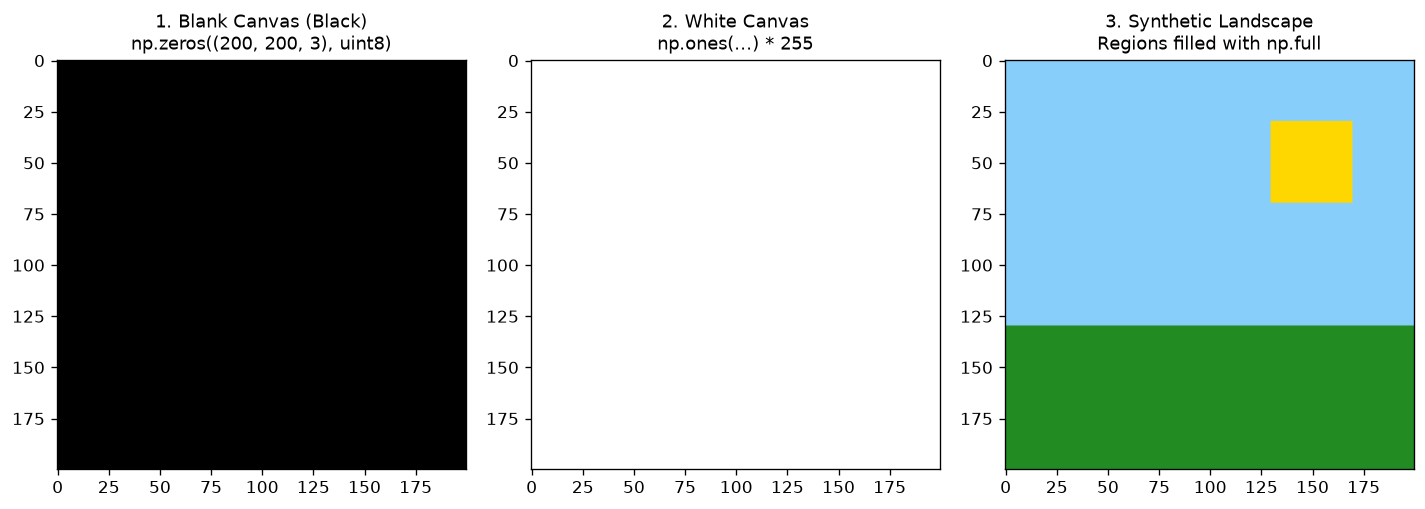

Array Shape: (200, 200, 3) (Height=200, Width=200, Channels=3)
Data Type: uint8 | Total Elements: 120,000


In [4]:
# 1. Blank 200x200x3 black canvas using np.zeros
canvas_black = np.zeros((200, 200, 3), dtype=np.uint8)

# 2. White canvas using np.ones with scalar multiplication
canvas_white = (np.ones((200, 200, 3), dtype=np.uint8) * 255)

# 3. Create a synthetic landscape by filling regions with np.full
canvas_landscape = np.zeros((200, 200, 3), dtype=np.uint8)

# Fill Sky region (top 130 rows) with Sky Blue [135, 206, 250]
canvas_landscape[0:130, :, :] = np.full((130, 200, 3), [135, 206, 250], dtype=np.uint8)

# Fill Ground region (bottom 70 rows) with Forest Green [34, 139, 34]
canvas_landscape[130:200, :, :] = np.full((70, 200, 3), [34, 139, 34], dtype=np.uint8)

# Draw a Golden Sun block in region rows 30:70, cols 130:170 using np.full with [255, 215, 0]
canvas_landscape[30:70, 130:170, :] = np.full((40, 40, 3), [255, 215, 0], dtype=np.uint8)

# Display the canvases
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(canvas_black)
axes[0].set_title("1. Blank Canvas (Black)\nnp.zeros((200, 200, 3), uint8)")
axes[0].axis("on")

axes[1].imshow(canvas_white)
axes[1].set_title("2. White Canvas\nnp.ones(...) * 255")
axes[1].axis("on")

axes[2].imshow(canvas_landscape)
axes[2].set_title("3. Synthetic Landscape\nRegions filled with np.full")
axes[2].axis("on")

plt.tight_layout()
plt.show()

print(f"Array Shape: {canvas_landscape.shape} (Height={canvas_landscape.shape[0]}, Width={canvas_landscape.shape[1]}, Channels={canvas_landscape.shape[2]})")
print(f"Data Type: {canvas_landscape.dtype} | Total Elements: {canvas_landscape.size:,}")


## 2. Drawing Color Blocks and Stripes using 3D Slicing

### Slicing Syntax
$$ \text{array}[\text{row\_start}:\text{row\_end},\; \text{col\_start}:\text{col\_end},\; \text{channel}] $$

- **Targeted Channel Modification:** Slicing `img[10:60, 20:90, 0] = 255` modifies **only the Red channel** for pixels in that bounding box, leaving Green and Blue unchanged.
- **Full RGB Assignment:** `img[y1:y2, x1:x2] = [R, G, B]` modifies all three color channels simultaneously.
- **Step Slicing for Stripes:** `img[y_start:y_end:step, :] = [R, G, B]` creates repetitive horizontal lines across the canvas.


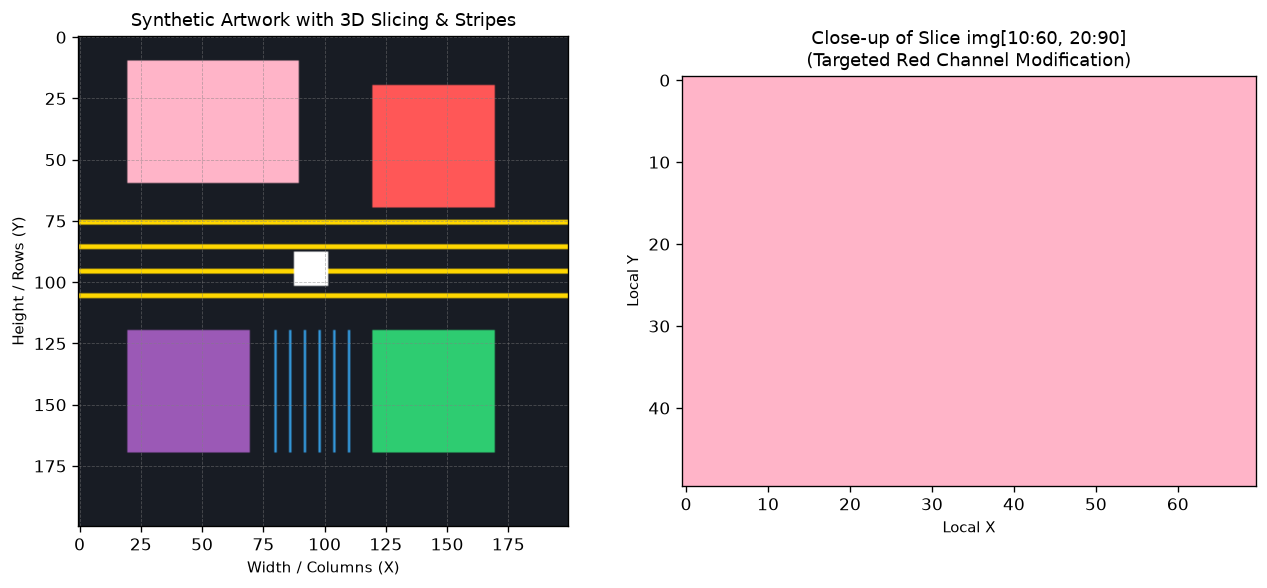

Pixel value at (row 35, col 55): R=255, G=180, B=200


In [5]:
# Create a dark canvas for our geometric composition
img = np.full((200, 200, 3), fill_value=[24, 28, 36], dtype=np.uint8)

# --- STEP 2A: Specific Assignment Requirement ---
# Create a cyan base block in rows 10:60, columns 20:90
img[10:60, 20:90] = [0, 180, 200]

# Now modify ONLY the Red channel in that exact slice:
img[10:60, 20:90, 0] = 255  # Adding full Red turns cyan into bright pastel pink/white!

# --- STEP 2B: Drawing additional geometric blocks across channels ---
img[20:70, 120:170]   = [255, 87, 87]    # Coral Red block
img[120:170, 20:70]   = [155, 89, 182]   # Royal Purple block
img[120:170, 120:170] = [46, 204, 113]   # Emerald Green block

# --- STEP 2C: Drawing Horizontal Stripes using step slicing ---
# Draw 2-pixel thick golden stripes every 10 rows from row 75 to 115
img[75:115:10, :, :] = [255, 215, 0]
img[76:115:10, :, :] = [255, 215, 0]

# --- STEP 2D: Drawing Vertical Pinstripes using step slicing ---
# Draw vertical lines in column range 80 to 115
img[120:170, 80:115:6, :] = [52, 152, 219]

# Center accent square
img[88:102, 88:102] = [255, 255, 255]

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(img)
axes[0].set_title("Synthetic Artwork with 3D Slicing & Stripes")
axes[0].set_xlabel("Width / Columns (X)")
axes[0].set_ylabel("Height / Rows (Y)")
axes[0].grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)

axes[1].imshow(img[10:60, 20:90])
axes[1].set_title("Close-up of Slice img[10:60, 20:90]\n(Targeted Red Channel Modification)")
axes[1].set_xlabel("Local X")
axes[1].set_ylabel("Local Y")

plt.tight_layout()
plt.show()

print(f"Pixel value at (row 35, col 55): R={img[35, 55, 0]}, G={img[35, 55, 1]}, B={img[35, 55, 2]}")


## 3. Cropping, Flipping (Negative Step Slicing), and Channel Extraction

### Manipulations
1. **Cropping (ROI - Region of Interest):**
   - Extract a sub-array by slicing: `cropped = img[50:150, 50:150]`
2. **Flipping with Negative Step Slicing (`::-1`):**
   - **Horizontal Flip:** `img[:, ::-1, :]` (reverses column index order)
   - **Vertical Flip:** `img[::-1, :, :]` (reverses row index order)
   - **180° Rotation:** `img[::-1, ::-1, :]` (reverses both axes)
3. **Channel Extraction & Isolation:**
   - Extract 2D intensity maps: `img[:, :, 0]` (Red), `img[:, :, 1]` (Green), `img[:, :, 2]` (Blue)
   - Isolate true 3D color channels by zeroing out the other two channels.


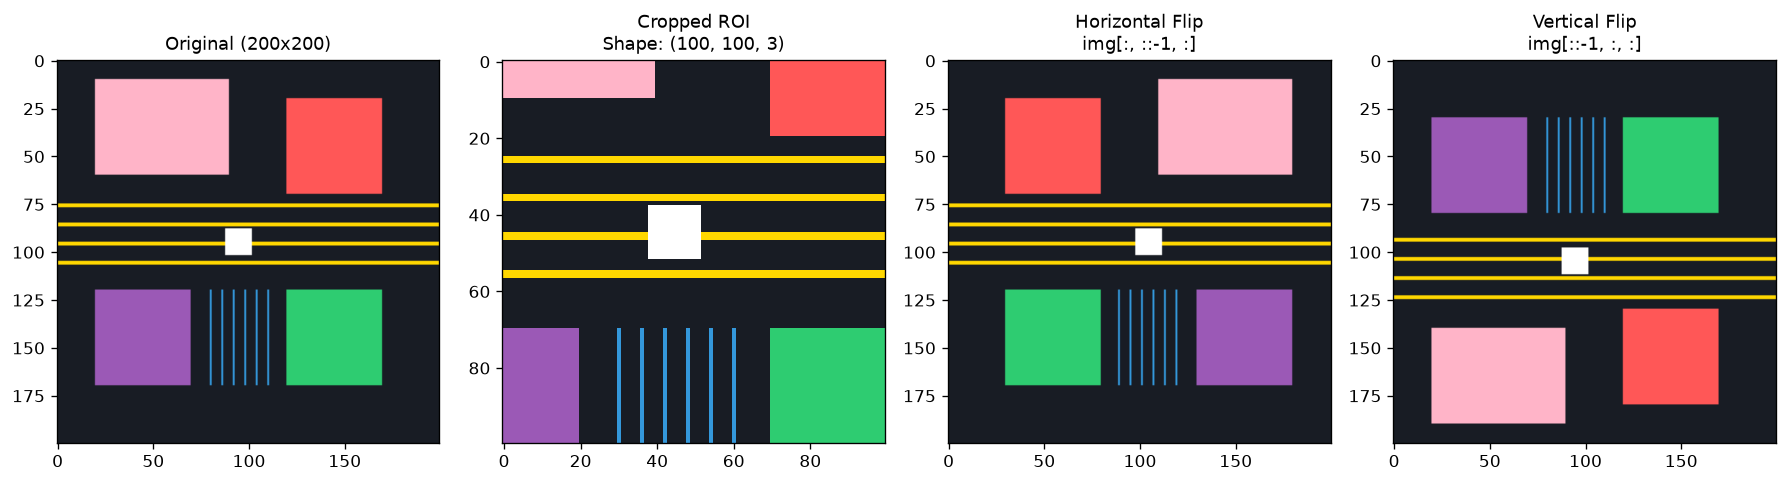

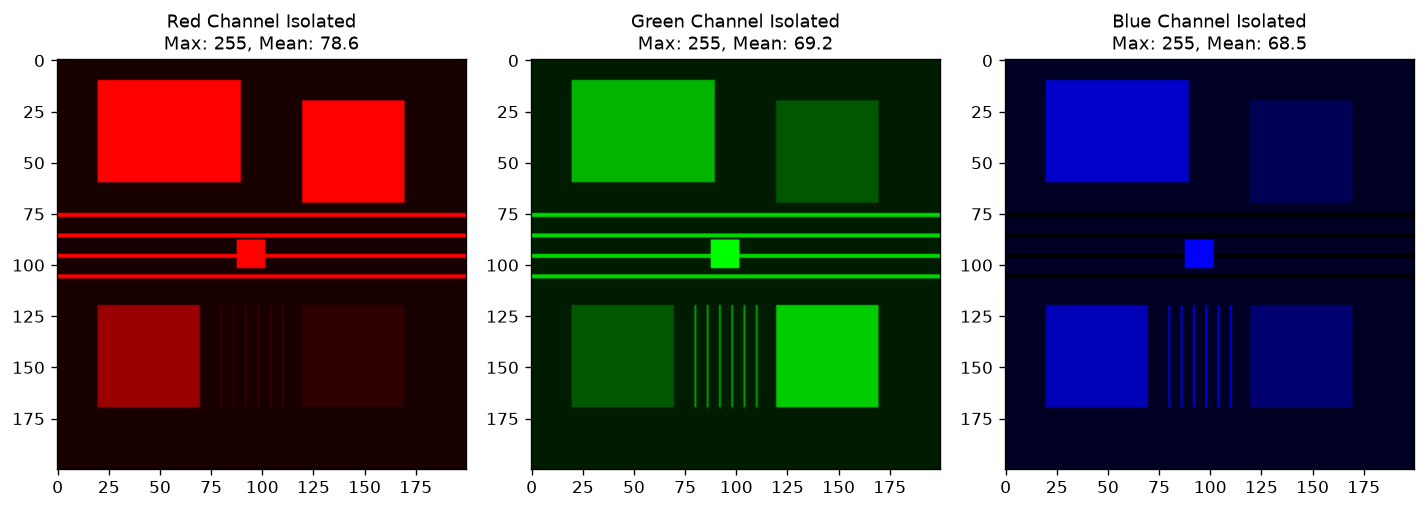

In [6]:
# 1. Cropping: Select central 100x100 region [50:150, 50:150]
cropped = img[50:150, 50:150]

# 2. Flipping using negative step slicing
flip_horizontal = img[:, ::-1, :]    # Mirror horizontally
flip_vertical   = img[::-1, :, :]    # Mirror vertically
flip_both       = img[::-1, ::-1, :] # 180-degree flip

# 3. Channel Extraction
r_channel = img[:, :, 0]
g_channel = img[:, :, 1]
b_channel = img[:, :, 2]

# Create isolated 3D images (only one channel active)
isolated_r = np.zeros_like(img)
isolated_r[:, :, 0] = r_channel

isolated_g = np.zeros_like(img)
isolated_g[:, :, 1] = g_channel

isolated_b = np.zeros_like(img)
isolated_b[:, :, 2] = b_channel

# Plot Cropping & Flipping
fig1, axes1 = plt.subplots(1, 4, figsize=(15, 3.8))
axes1[0].imshow(img)
axes1[0].set_title("Original (200x200)")

axes1[1].imshow(cropped)
axes1[1].set_title(f"Cropped ROI\nShape: {cropped.shape}")

axes1[2].imshow(flip_horizontal)
axes1[2].set_title("Horizontal Flip\nimg[:, ::-1, :]")

axes1[3].imshow(flip_vertical)
axes1[3].set_title("Vertical Flip\nimg[::-1, :, :]")

for ax in axes1:
    ax.axis("on")
plt.tight_layout()
plt.show()

# Plot Isolated Channels
fig2, axes2 = plt.subplots(1, 3, figsize=(12, 4))
axes2[0].imshow(isolated_r)
axes2[0].set_title(f"Red Channel Isolated\nMax: {r_channel.max()}, Mean: {r_channel.mean():.1f}")

axes2[1].imshow(isolated_g)
axes2[1].set_title(f"Green Channel Isolated\nMax: {g_channel.max()}, Mean: {g_channel.mean():.1f}")

axes2[2].imshow(isolated_b)
axes2[2].set_title(f"Blue Channel Isolated\nMax: {b_channel.max()}, Mean: {b_channel.mean():.1f}")

for ax in axes2:
    ax.axis("on")
plt.tight_layout()
plt.show()


## 4. Brightness/Darkness (`astype(float32)` & uint8 Pitfalls) and Boolean Masking

### The Critical `uint8` Overflow Trap
In Python with NumPy, `uint8` integers only store values from **0 to 255**:
- $200 + 100 = 300 \implies 300 \pmod{256} = \mathbf{44}$ (Wrap-around / Overflow!)
- $50 - 100 = -50 \implies 256 - 50 = \mathbf{206}$ (Underflow!)

### The Safe Image Processing Pipeline
1. Cast from `uint8` to `np.float32`: `img_float = img.astype(np.float32)`
2. Perform arithmetic (scale or offset)
3. Clamp values to legal range $[0, 255]$ with `np.clip(result, 0, 255)`
4. Cast back to `np.uint8`: `result.astype(np.uint8)`

### Boolean Masking
- A condition like `(luminance > threshold)` produces a 2D boolean array of `True` and `False`.
- `np.count_nonzero(mask)` counts matching pixels.
- `img[mask] = [R, G, B]` reassigns matching pixels in place!


THE UINT8 OVERFLOW HAZARD DEMONSTRATION
Original uint8 values:      [150 200 250]
Direct + 100 in uint8:      [250  44  94]  <-- Overflow! (200 + 100 wrapped to 44)
Safe float32 + clip result: [250 255 255]  <-- Properly capped at 255!

BOOLEAN MASKING METRICS
Mask shape: (200, 200) | Mask dtype: bool
Bright pixels identified: 13,068 / 40,000 (32.67%)


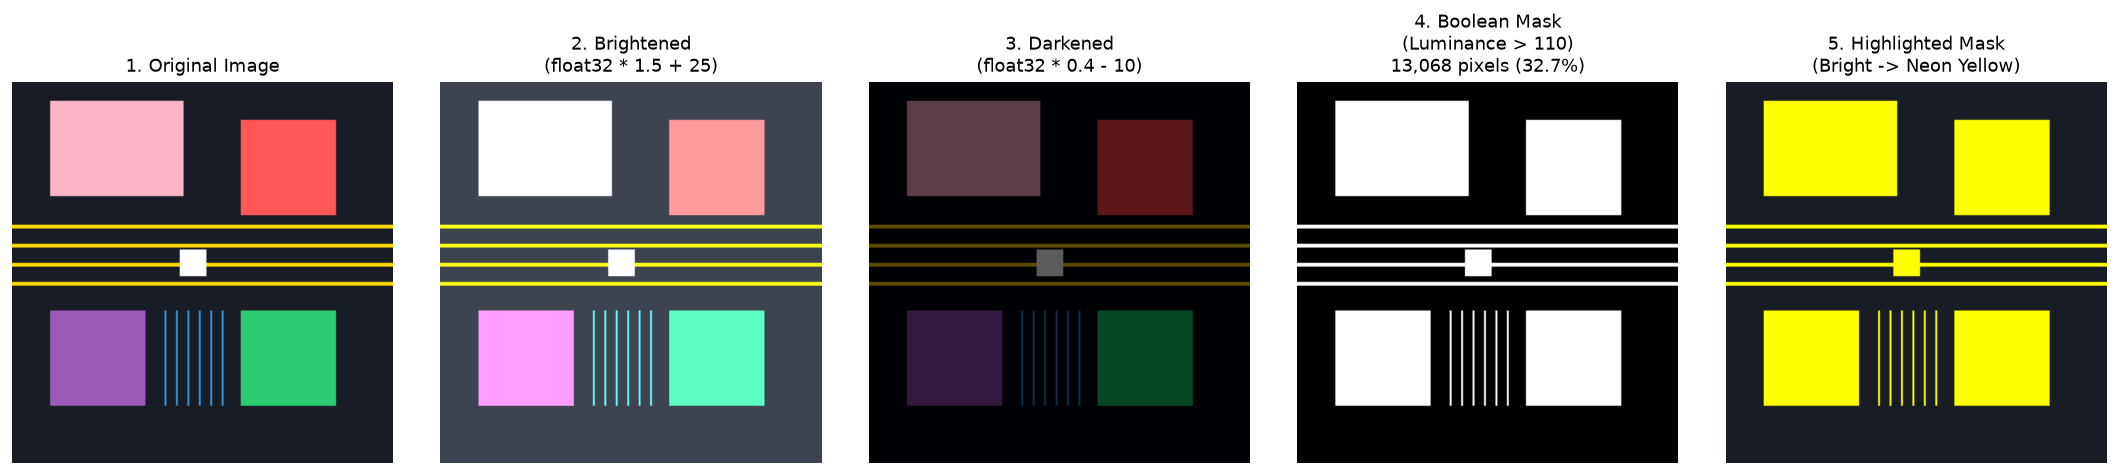

In [7]:
# Part A: Demonstrating the uint8 Overflow Bug
test_uint8 = np.array([150, 200, 250], dtype=np.uint8)
print("=" * 60)
print("THE UINT8 OVERFLOW HAZARD DEMONSTRATION")
print("=" * 60)
print(f"Original uint8 values:      {test_uint8}")
print(f"Direct + 100 in uint8:      {test_uint8 + np.uint8(100)}  <-- Overflow! (200 + 100 wrapped to 44)")

# Safe calculation using float32
test_float = test_uint8.astype(np.float32)
test_safe  = np.clip(test_float + 100, 0, 255).astype(np.uint8)
print(f"Safe float32 + clip result: {test_safe}  <-- Properly capped at 255!\n")

# Part B: Brightening and Darkening the Synthetic Image
img_float = img.astype(np.float32)

# Brighten: scale up by 1.5x and add offset +25
img_bright = np.clip(img_float * 1.5 + 25, 0, 255).astype(np.uint8)

# Darken: scale down by 0.4x and subtract offset -10
img_dark = np.clip(img_float * 0.4 - 10, 0, 255).astype(np.uint8)

# Part C: Boolean Masking to Find Bright Pixels
# Perceived luminance: Y = 0.299*R + 0.587*G + 0.114*B
luminance = (0.299 * img_float[:, :, 0] + 
             0.587 * img_float[:, :, 1] + 
             0.114 * img_float[:, :, 2])

# Threshold mask: find all pixels with luminance > 110
bright_mask = luminance > 110

bright_pixels_count = np.count_nonzero(bright_mask)
total_pixels = bright_mask.size
pct_bright = (bright_pixels_count / total_pixels) * 100

print("=" * 60)
print("BOOLEAN MASKING METRICS")
print("=" * 60)
print(f"Mask shape: {bright_mask.shape} | Mask dtype: {bright_mask.dtype}")
print(f"Bright pixels identified: {bright_pixels_count:,} / {total_pixels:,} ({pct_bright:.2f}%)")

# Apply Mask: Color Splash / Neon Highlight
img_highlighted = img.copy()
img_highlighted[bright_mask] = [255, 255, 0] # Highlight bright regions with Neon Yellow

# Multi-panel visualization
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))

axes[0].imshow(img)
axes[0].set_title("1. Original Image")

axes[1].imshow(img_bright)
axes[1].set_title("2. Brightened\n(float32 * 1.5 + 25)")

axes[2].imshow(img_dark)
axes[2].set_title("3. Darkened\n(float32 * 0.4 - 10)")

axes[3].imshow(bright_mask, cmap='gray')
axes[3].set_title(f"4. Boolean Mask\n(Luminance > 110)\n{bright_pixels_count:,} pixels ({pct_bright:.1f}%)")

axes[4].imshow(img_highlighted)
axes[4].set_title("5. Highlighted Mask\n(Bright -> Neon Yellow)")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Memory Comparison (`uint8` vs `float64`) using `nbytes` & `plt.imshow`

### Understanding Array Memory
- `.itemsize`: Number of bytes consumed by a single element.
- `.size`: Total number of elements across all dimensions ($H \times W \times C$).
- `.nbytes`: Total memory allocated in bytes (`size * itemsize`).

| Data Type | Bytes per Element | Memory Overhead | Typical Use Case |
| :--- | :--- | :--- | :--- |
| **`uint8`** | 1 byte | **1x (Baseline)** | Image storage, files (PNG/JPEG), display |
| **`float32`** | 4 bytes | **4x** | Deep Learning training, GPU acceleration, PyTorch/TensorFlow |
| **`float64`** | 8 bytes | **8x** | High-precision scientific computing, default NumPy float |

---

### The `plt.imshow` Normalization Rule
Matplotlib's `imshow` function behaves differently depending on the input dtype:
1. **Integer types (`uint8`):** Expects values in $[0, 255]$.
2. **Float types (`float32` / `float64`):** Expects normalized values in **$[0.0, 1.0]$**!
   - If an unscaled float array with values up to $255$ is passed, any value $\ge 1.0$ is clipped to pure white!
   - Therefore, float images must always be normalized via `img_float / 255.0` before passing to `plt.imshow`.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


Data Type                           | Item Size  | Total Bytes  | Size (KB)  | Multiplier
uint8 (Standard Image)              | 1 bytes    | 120,000      | 117.19     | 1.0x
float32 (Deep Learning / GPU)       | 4 bytes    | 480,000      | 468.75     | 4.0x
float64 (Default NumPy float)       | 8 bytes    | 960,000      | 937.50     | 8.0x

Real-World Scale: Single 4K Image (3840 x 2160 x 3 = 24,883,200 elements):
  • uint8:   23.73 MB
  • float32: 94.92 MB
  • float64: 189.84 MB  <-- 8x memory consumption!



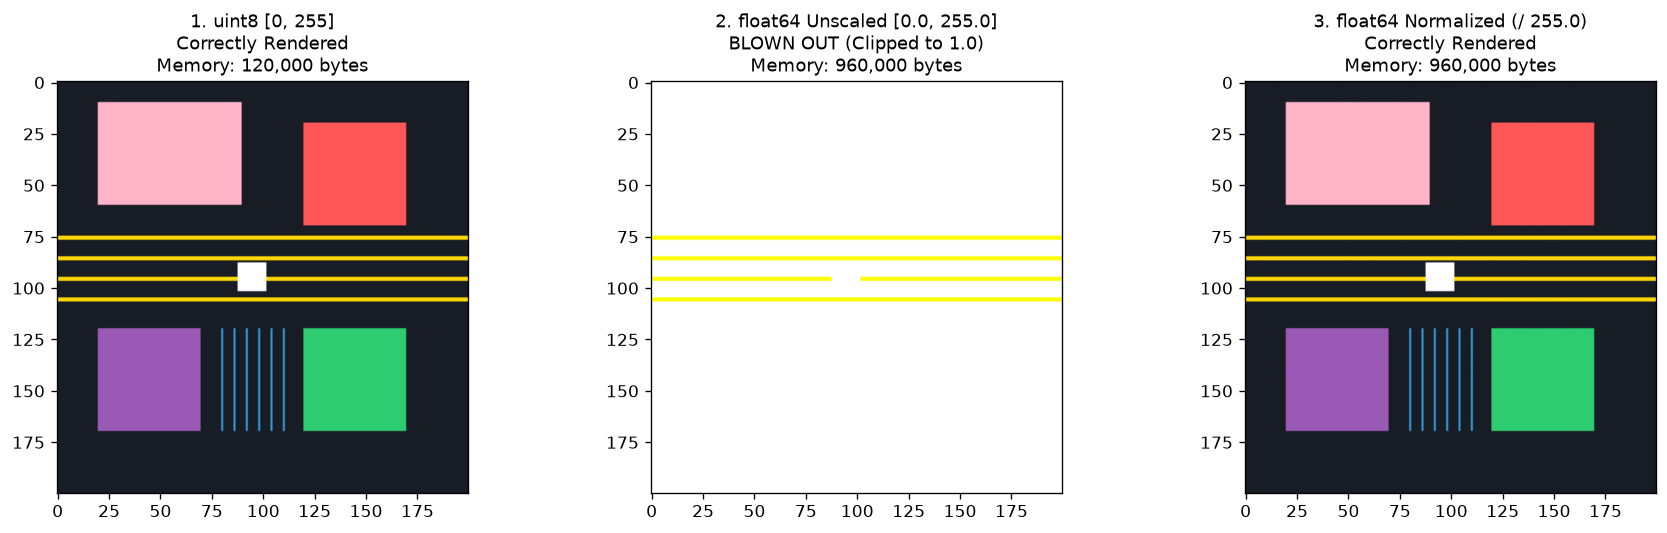

In [8]:
# 1. Memory inspection using nbytes
img_u8  = img
img_f32 = img.astype(np.float32)
img_f64 = img.astype(np.float64)

dtypes_list = [
    ("uint8 (Standard Image)", img_u8),
    ("float32 (Deep Learning / GPU)", img_f32),
    ("float64 (Default NumPy float)", img_f64)
]

print("=" * 82)
print(f"{'Data Type':<35} | {'Item Size':<10} | {'Total Bytes':<12} | {'Size (KB)':<10} | {'Multiplier'}")
print("=" * 82)

base_bytes = img_u8.nbytes
for label, arr in dtypes_list:
    nb = arr.nbytes
    kb = nb / 1024
    mult = nb / base_bytes
    print(f"{label:<35} | {arr.itemsize} bytes    | {nb:<12,} | {kb:<10.2f} | {mult:.1f}x")
print("=" * 82)

# Real-world high resolution comparison
h_4k, w_4k = 2160, 3840
num_4k_elems = h_4k * w_4k * 3
print(f"\nReal-World Scale: Single 4K Image (3840 x 2160 x 3 = {num_4k_elems:,} elements):")
print(f"  • uint8:   {(num_4k_elems * 1) / (1024**2):.2f} MB")
print(f"  • float32: {(num_4k_elems * 4) / (1024**2):.2f} MB")
print(f"  • float64: {(num_4k_elems * 8) / (1024**2):.2f} MB  <-- 8x memory consumption!\n")

# 2. Visual Demonstration: plt.imshow with uint8 vs float64
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Plot 1: uint8 image (correct display)
axes[0].imshow(img_u8)
axes[0].set_title(f"1. uint8 [0, 255]\nCorrectly Rendered\nMemory: {img_u8.nbytes:,} bytes")

# Plot 2: Unscaled float64 (Clipping Bug: > 1.0 clamped to White!)
axes[1].imshow(img_f64)
axes[1].set_title(f"2. float64 Unscaled [0.0, 255.0]\nBLOWN OUT (Clipped to 1.0)\nMemory: {img_f64.nbytes:,} bytes")

# Plot 3: Properly normalized float64 [0.0, 1.0]
axes[2].imshow(img_f64 / 255.0)
axes[2].set_title(f"3. float64 Normalized (/ 255.0)\nCorrectly Rendered\nMemory: {img_f64.nbytes:,} bytes")

for ax in axes:
    ax.axis("on")
plt.tight_layout()
plt.show()


## 6. Comprehensive Synthetic Image Generator Toolkit (Modular OOP)

We can now encapsulate all the NumPy techniques developed above into a clean, reusable Python class: **`SyntheticImageGenerator`**.

### Capabilities
- **Gradients:** Smooth vertical/horizontal color transitions using linear interpolation and broadcasting
- **Shapes:** Rectangles, circles (using Euclidean distance array broadcasting), and diamond cores
- **Procedural Patterns:** Horizontal & vertical stripes using step slicing
- **Analogue Noise:** Adding Gaussian sensor noise using `np.random.normal`


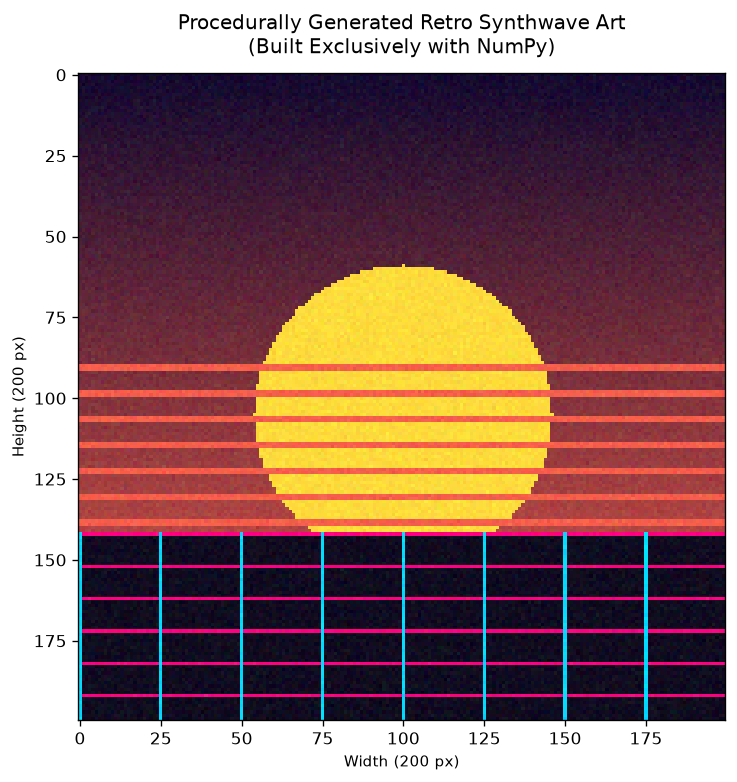

Synthetic artwork generated successfully! Shape: (200, 200, 3), dtype: uint8


In [9]:
class SyntheticImageGenerator:
    """
    A modular synthetic image generator built exclusively with NumPy.
    Supports linear gradients, geometric shapes, procedural stripes, and noise.
    """
    def __init__(self, height=200, width=200, bg_color=(20, 20, 30)):
        self.height = height
        self.width = width
        self.img = np.full((height, width, 3), fill_value=bg_color, dtype=np.uint8)

    def add_vertical_gradient(self, top_color, bottom_color):
        """Creates a smooth linear vertical gradient using broadcasting."""
        top = np.array(top_color, dtype=np.float32)
        bottom = np.array(bottom_color, dtype=np.float32)
        # 1D interpolation vector across height
        t = np.linspace(0.0, 1.0, self.height, dtype=np.float32)[:, None, None]
        # Calculate gradient across height (H, 1, 3) and tile across width (H, W, 3)
        gradient = (1.0 - t) * top + t * bottom
        gradient = np.repeat(gradient, self.width, axis=1)
        self.img = np.clip(gradient, 0, 255).astype(np.uint8)
        return self

    def add_rectangle(self, y1, y2, x1, x2, color):
        """Draws a solid colored rectangle using 2D/3D slicing."""
        self.img[y1:y2, x1:x2] = color
        return self

    def add_circle(self, center_y, center_x, radius, color):
        """Draws a smooth circle using Euclidean distance and boolean masking."""
        y, x = np.ogrid[:self.height, :self.width]
        dist_from_center = np.sqrt((y - center_y)**2 + (x - center_x)**2)
        mask = dist_from_center <= radius
        self.img[mask] = color
        return self

    def add_stripes(self, start_y, end_y, step=8, thickness=2, color=(255, 255, 255)):
        """Draws horizontal stripes using slice steps."""
        for offset in range(thickness):
            self.img[start_y + offset : end_y : step, :] = color
        return self

    def add_gaussian_noise(self, sigma=8):
        """Injects random Gaussian noise using np.random.normal."""
        noise = np.random.normal(0, sigma, (self.height, self.width, 3))
        img_f = self.img.astype(np.float32) + noise
        self.img = np.clip(img_f, 0, 255).astype(np.uint8)
        return self

    def get_image(self):
        """Returns a copy of the generated uint8 image array."""
        return self.img.copy()

# Generate a Retro Synthwave Artwork entirely from scratch with NumPy
np.random.seed(42)  # For reproducible aesthetic output

generator = SyntheticImageGenerator(height=200, width=200)

# 1. Sky vertical gradient (Deep Violet to Sunset Orange)
generator.add_vertical_gradient(top_color=[20, 10, 48], bottom_color=[245, 95, 75])

# 2. Glowing Golden Sun in the center
generator.add_circle(center_y=105, center_x=100, radius=46, color=[255, 220, 60])

# 3. Retro horizontal stripes cutting through the bottom half of the sun
generator.add_stripes(start_y=90, end_y=140, step=8, thickness=2, color=[245, 95, 75])

# 4. Dark reflective horizon floor
generator.add_rectangle(y1=142, y2=200, x1=0, x2=200, color=[16, 12, 32])

# 5. Perspective Grid lines using step slicing
generator.img[142:200:10, :] = [255, 0, 128]      # Neon pink horizontal lines
generator.img[142:200, ::25] = [0, 220, 255]      # Cyan vertical perspective lines

# 6. Add subtle analogue film grain noise
generator.add_gaussian_noise(sigma=6)

synthetic_artwork = generator.get_image()

# Display the generated artwork
plt.figure(figsize=(7, 7))
plt.imshow(synthetic_artwork)
plt.title("Procedurally Generated Retro Synthwave Art\n(Built Exclusively with NumPy)", fontsize=12, pad=12)
plt.xlabel("Width (200 px)")
plt.ylabel("Height (200 px)")
plt.grid(False)
plt.show()

print(f"Synthetic artwork generated successfully! Shape: {synthetic_artwork.shape}, dtype: {synthetic_artwork.dtype}")


## 7. Applying the Toolkit to Real Images (`Sample_128x128.png`)

We can apply the exact same NumPy array slicing, channel extraction, and boolean masking operations to real images loaded from disk.


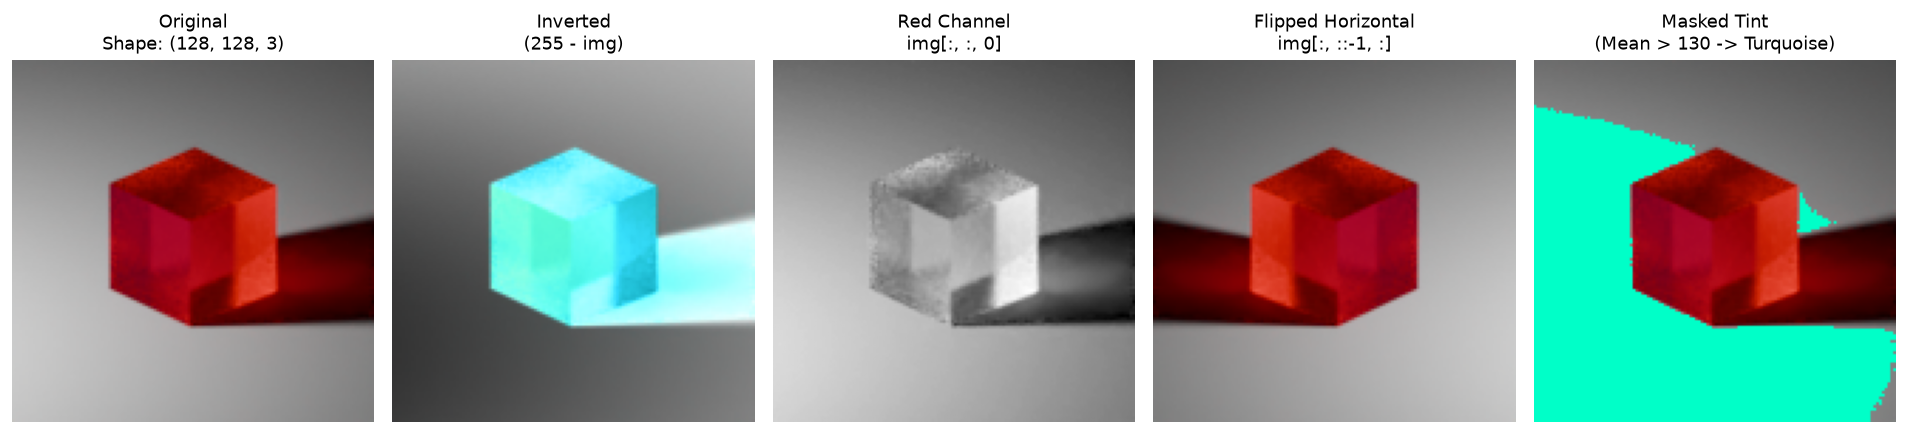

Successfully processed Sample_128x128.png with NumPy!


In [11]:
# Load sample image located in the workspace
image_path = "Sample_128x128.png"

try:
    pil_img = Image.open(image_path)
    raw_array = np.array(pil_img)
    
    # Handle RGBA images by slicing only the first 3 color channels (RGB)
    if raw_array.ndim == 3 and raw_array.shape[2] == 4:
        sample_rgb = raw_array[:, :, :3]
    else:
        sample_rgb = raw_array

    # 1. Invert colors (Negative filter)
    inverted = 255 - sample_rgb
    
    # 2. Extract Red Channel
    red_ch = sample_rgb[:, :, 0]
    
    # 3. Horizontal Flip using negative step slicing
    flipped_sample = sample_rgb[:, ::-1, :]
    
    # 4. Boolean mask for bright areas
    bright_mask_sample = sample_rgb.mean(axis=2) > 130
    tinted_sample = sample_rgb.copy()
    tinted_sample[bright_mask_sample] = [0, 255, 200] # Turquoise highlight

    # Plot comparisons
    fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
    axes[0].imshow(sample_rgb)
    axes[0].set_title(f"Original\nShape: {sample_rgb.shape}")
    
    axes[1].imshow(inverted)
    axes[1].set_title("Inverted\n(255 - img)")
    
    axes[2].imshow(red_ch, cmap='gray')
    axes[2].set_title("Red Channel\nimg[:, :, 0]")
    
    axes[3].imshow(flipped_sample)
    axes[3].set_title("Flipped Horizontal\nimg[:, ::-1, :]")
    
    axes[4].imshow(tinted_sample)
    axes[4].set_title("Masked Tint\n(Mean > 130 -> Turquoise)")
    
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    print("Successfully processed Sample_128x128.png with NumPy!")
except Exception as e:
    print(f"Note: Could not load {image_path}: {e}")


## 8. Summary & Key Takeaways

### Core Principles Mastered
1. **Array Anatomy:** Digital images are 3D arrays of shape `(Height, Width, Channels)` with `np.uint8` intensity values $\in [0, 255]$.
2. **Region Creation & Slicing:**
   - Blank / solid canvases: `np.zeros`, `np.ones`, `np.full`
   - Slicing regions: `img[y1:y2, x1:x2, c]`
   - Step slicing for patterns/stripes: `img[start:end:step, :]`
   - Negative step slicing for flipping: `img[:, ::-1, :]` (horizontal) and `img[::-1, :, :]` (vertical)
3. **Arithmetic Safety:** Never add/subtract directly in `uint8` due to modulo wrap-around overflow. Cast to `float32`, clip to $[0, 255]$, then cast back to `uint8`.
4. **Boolean Masking:** Identify, count, and recolor pixels meeting specific intensity or color conditions.
5. **Memory & Display Rules:**
   - `float64` consumes 8x the memory of `uint8` ($O(8N)$ vs $O(N)$).
   - In `plt.imshow`, integer images require $[0, 255]$ while floating-point images require normalized $[0.0, 1.0]$.

---
